# Analisis Sentimen Pada Ulasan Aplikasi Gojek

Analisis sentimen dengan studi kasus ulasan aplikasi Gojek, dimulai dari memahami data dan membersihkan teks hingga mengelompokkan ulasan menjadi positif, netral, dan negatif serta membaca hasilnya.

Label sentimen dibuat dari rating pengguna, dan tahapan analisis mencakup pemeriksaan data, pelabelan, pembersihan dan normalisasi teks, pembagian data, visualisasi kata, ekstraksi fitur TF-IDF, pemodelan, serta evaluasi dan interpretasi hasil. Naive Bayes dan Logistic Regression digunakan sebagai contoh penerapan pada tahap pemodelan.

## 1. Loading Data

Data ulasan dibaca dari CSV menggunakan pandas.


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Baca data ulasan dan simpan jumlah awal untuk tabel ringkasan.
df = pd.read_csv('Data/GojekAppReviewV4.0.0-V4.9.3_Cleaned.csv')
jumlah_awal = len(df)
print('Jumlah baris:', jumlah_awal)
df.head()

Jumlah baris: 225002


,userName,content,score,at,appVersion
0,Yuga Edit,akun gopay saya di blok,1,2022-01-21 10:52:12,4.9.3
1,ff burik,Lambat sekali sekarang ini bosssku apk gojek g...,3,2021-11-30 15:40:38,4.9.3
2,Anisa Suci Rahmayuliani,Kenapa sih dari kemarin sy buka aplikasi gojek...,4,2021-11-29 22:58:12,4.9.3
3,naoki yakuza,Baru download gojek dan hape baru trus ditop u...,1,2022-09-03 15:21:17,4.9.3
4,Trio Sugianto,Mantap,5,2022-01-15 10:05:27,4.9.3


Data memuat teks ulasan pada `content` dan rating pada `score`.

## 2. Memeriksa Data Quality

Periksa nilai kosong, teks duplikat, dan jumlah ulasan untuk setiap rating sebelum melakukan pembersihan.

In [39]:
# Periksa nilai kosong dan teks yang berulang.
print('Nilai kosong per kolom:')
print(df.isna().sum())
print('\nTeks ulasan duplikat:', df.duplicated(subset='content').sum())

Nilai kosong per kolom:
userName      0
content       2
score         0
at            0
appVersion    0
dtype: int64

Teks ulasan duplikat: 86183


score
1     45208
2      8933
3      9450
4     14307
5    146992
Name: count, dtype: int64


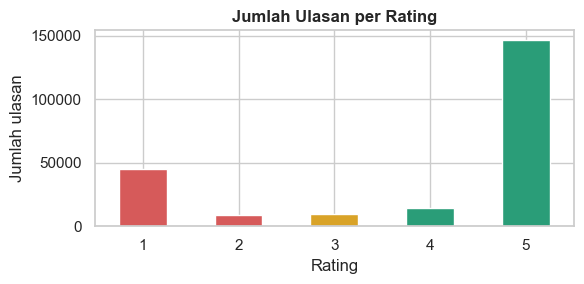

In [54]:
# Gunakan warna yang sama untuk kelas sentimen pada semua grafik.
warna_sentimen = {'positif': '#2A9D78', 'netral': '#D9A328', 'negatif': '#D65A5A'}
urutan_sentimen = ['positif', 'netral', 'negatif']
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.titleweight': 'bold'})

# Rating 1-2 negatif, 3 netral, dan 4-5 positif.
score_counts = df['score'].value_counts().sort_index()
warna_rating = [warna_sentimen['negatif'], warna_sentimen['negatif'], warna_sentimen['netral'], warna_sentimen['positif'], warna_sentimen['positif']]
print(score_counts)
score_counts.plot.bar(color=warna_rating, figsize=(6, 3))
plt.title('Jumlah Ulasan per Rating')
plt.xlabel('Rating')
plt.ylabel('Jumlah ulasan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Rating 5 memiliki ulasan paling banyak. Data tidak seimbang dan beberapa teks berulang, sehingga akurasi saja belum cukup untuk menilai model.

## 3. Pelabelan Sentimen Pada Dataset

Rating 1 dan 2 diberi label negatif, 3 netral, serta 4 dan 5 positif. 
Label ini merupakan perkiraan dari rating; isi teks dapat berbeda dari ratingnya.

In [41]:
# Buat label dari rating, bukan dari isi ulasan.
def label_sentimen(score):
    if score <= 2:
        return 'negatif'
    elif score == 3:
        return 'netral'
    return 'positif'

df['sentimen'] = df['score'].apply(label_sentimen)
jumlah_label = df['sentimen'].value_counts().rename('Jumlah').to_frame()
jumlah_label['Persentase'] = jumlah_label['Jumlah'] / len(df) * 100
display(jumlah_label.round(2))

,Jumlah,Persentase
sentimen,,
positif,161371,71.72
negatif,54171,24.08
netral,9460,4.20


Tabel memperlihatkan kelas positif lebih banyak daripada netral.

## 4. Membersihkan Teks

Mengubah huruf menjadi kecil, menghapus URL, angka, dan tanda baca, lalu merapikan spasi. Buang nilai kosong serta ulasan yang tidak lagi berisi teks. Pada latihan ini emoji ikut dihapus, meskipun bisa membawa makna sentimen.

In [42]:
# Bersihkan nilai kosong sebelum konversi teks agar NaN tidak menjadi kata 'nan'.
import re

def bersihkan_teks(teks):
    """Pembersihan baseline untuk satu ulasan."""
    if pd.isna(teks):
        return ''
    teks = str(teks).lower()
    teks = re.sub(r'http\S+|www\S+', ' ', teks)  # Hapus URL.
    teks = re.sub(r'@\w+|#\w+', ' ', teks)  # Hapus mention dan hashtag.
    teks = re.sub(r'\d+', ' ', teks)  # Hapus angka.
    teks = re.sub(r'[^a-z\s]', ' ', teks)  # Sisakan huruf ASCII dan spasi.
    return re.sub(r'\s+', ' ', teks).strip()

n_sebelum = len(df)
df = df.dropna(subset=['content']).copy()
df['text_clean'] = df['content'].apply(bersihkan_teks)
df = df[df['text_clean'].str.len() > 0].copy()
print(f'Baris sebelum: {n_sebelum:,}; sesudah: {len(df):,}')
print(df[['content', 'text_clean']].head(3).to_string(index=False))

Baris sebelum: 225,002; sesudah: 224,890
                                                                                                                                 content                                                                                                                           text_clean
                                                                                                                 akun gopay saya di blok                                                                                                              akun gopay saya di blok
                                                                               Lambat sekali sekarang ini bosssku apk gojek gk kaya dulu                                                                            lambat sekali sekarang ini bosssku apk gojek gk kaya dulu
Kenapa sih dari kemarin sy buka aplikasi gojek malah keluar sendiri terus Saya kasih bintang 2 dulu kalo sudah normal sy kasih bintang 7 kenapa sih d

Kolom `text_clean` menyimpan teks bersih.

## 5. Split Data: Train, Validation, Test

Data latih digunakan untuk belajar, validasi untuk memilih model, dan uji untuk menilai model terpilih. Pembagian berdasarkan kelompok teks menjaga ulasan identik dalam subset yang sama. Targetnya sekitar 60/20/20, jumlah aktual dapat berbeda dikarenakan ukuran kelompoknya.

In [43]:
# Bagi data sebelum preprocessing NLP dan pembelajaran fitur.
from sklearn.model_selection import StratifiedGroupKFold

# Teks bersih identik dikelompokkan agar duplikasi tidak melintasi subset.
pembagi_uji = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
indeks_sisa, indeks_uji = next(pembagi_uji.split(df['text_clean'], df['sentimen'], groups=df['text_clean']))
data_sisa = df.iloc[indeks_sisa].copy()
data_uji = df.iloc[indeks_uji].copy()
pembagi_validasi = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=43)
indeks_latih, indeks_validasi = next(pembagi_validasi.split(data_sisa['text_clean'], data_sisa['sentimen'], groups=data_sisa['text_clean']))
data_latih = data_sisa.iloc[indeks_latih].copy()
data_validasi = data_sisa.iloc[indeks_validasi].copy()

# Verifikasi kelompok dan tampilkan proporsi aktual; target sekitar 60/20/20.
assert set(data_latih['text_clean']).isdisjoint(data_validasi['text_clean'])
assert set(data_latih['text_clean']).isdisjoint(data_uji['text_clean'])
assert set(data_validasi['text_clean']).isdisjoint(data_uji['text_clean'])
for nama, bagian in [('Latih', data_latih), ('Validasi', data_validasi), ('Uji', data_uji)]:
    print(f'{nama}: {len(bagian):,} ulasan ({len(bagian) / len(df):.1%})')
    print(bagian['sentimen'].value_counts(normalize=True).round(3))

Latih: 137,939 ulasan (61.3%)
sentimen
positif    0.722
negatif    0.236
netral     0.042
Name: proportion, dtype: float64
Validasi: 37,359 ulasan (16.6%)
sentimen
positif    0.662
negatif    0.289
netral     0.049
Name: proportion, dtype: float64
Uji: 49,592 ulasan (22.1%)
sentimen
positif    0.745
negatif    0.217
netral     0.038
Name: proportion, dtype: float64


Pembagian menghasilkan tiga subset dengan kelompok teks yang terpisah.

## 6. Normalisasi, Stopwords, dan Stemming

Ubah `ga`, `gk`, `gak`, `nggak`, dan `enggak` menjadi `tidak`; ubah `aja` menjadi `saja`. Buang token pengisi `nya` dan `saja` bersama stopwords Sastrawi dan NLTK. Negasi tetap digunakan model agar `tidak bagus` tidak berubah menjadi `bagus`.

Stemming Sastrawi aktif: kata berimbuhan diubah ke bentuk dasar, misalnya `membantu` menjadi `bantu`. Hasil tiap kata disimpan dalam cache JSON dan progres disimpan setiap 1.000 teks. Proses pertama pada dataset ini mencatat sekitar 13,3 jam; cache menghindari stemming ulang kata yang sudah tersedia. Kata slang yang belum masuk kamus normalisasi belum tentu menjadi baku.

In [80]:
# Siapkan stopwords dan normalisasi kata tidak baku.
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.corpus import stopwords as nltk_stopwords
from pathlib import Path
import json
import nltk
import time

try:
    stopword_nltk = set(nltk_stopwords.words('indonesian'))
except LookupError:
    nltk.download('stopwords', quiet=True, raise_on_error=True)
    stopword_nltk = set(nltk_stopwords.words('indonesian'))
stopword_sastrawi = set(StopWordRemoverFactory().get_stop_words())
negasi = {'tidak', 'tak', 'bukan', 'belum', 'jangan', 'tanpa'}
kamus_normalisasi = {'ga': 'tidak', 'gk': 'tidak', 'gak': 'tidak', 'nggak': 'tidak', 'enggak': 'tidak', 'aja': 'saja'}
stopword_tambahan = {'nya', 'saja'}
stop_words = (stopword_sastrawi | stopword_nltk | stopword_tambahan) - negasi

# Negasi tetap dipakai model, tetapi disembunyikan dari grafik frekuensi kata.
stopword_visual = stop_words | negasi | set(kamus_normalisasi)
GUNAKAN_STEMMING = True
stemmer = StemmerFactory().create_stemmer()
cache_stem_path = Path('outputs/cache_stem_sastrawi_v1.json')
kamus_stem = json.loads(cache_stem_path.read_text(encoding='utf-8')) if cache_stem_path.exists() else {}

def stem_dengan_cache(kata):
    if kata in negasi or not GUNAKAN_STEMMING:
        return kata
    if kata not in kamus_stem:
        kamus_stem[kata] = stemmer.stem(kata)
    return kamus_stem[kata]

def preprocessing_teks(teks):
    # Normalisasi dahulu, baru hapus stopwords dan lakukan stemming.
    token = [kamus_normalisasi.get(kata, kata) for kata in teks.split()]
    token = [stem_dengan_cache(kata) for kata in token if kata not in stop_words]
    return ' '.join(kata for kata in token if kata not in stop_words)

assert preprocessing_teks('gak bagus') == 'tidak bagus'
assert preprocessing_teks('membantu') == 'bantu'
assert preprocessing_teks('nyaman') == 'nyaman'
assert not {'nya', 'ga', 'gk', 'gak', 'aja', 'tidak'} - stopword_visual
print('Stemming aktif:', GUNAKAN_STEMMING)
print('Kata dalam cache:', len(kamus_stem))
print('Contoh:', preprocessing_teks('aplikasi nya membantu tapi gak bagus aja'))

Stemming aktif: True
Kata dalam cache: 3
Contoh: aplikasi bantu tidak bagus


Kata seperti `yang` dan `dan` dibuang, tetapi negasi seperti `tidak` tetap disimpan.

### Preprocessing

Proses setiap teks unik, lalu petakan hasilnya ke semua baris. buang teks kosong dan hasil preprocessing yang sudah muncul di subset sebelumnya. Penyaringan ini mengubah jumlah data, dan hasil evaluasi berlaku pada baris yang tersisa.

In [81]:
# Pulihkan subset sebelum filter agar sel ini aman dijalankan ulang.
data_sisa = df.iloc[indeks_sisa].copy()
data_latih = data_sisa.iloc[indeks_latih].copy()
data_validasi = data_sisa.iloc[indeks_validasi].copy()
data_uji = df.iloc[indeks_uji].copy()

t0 = time.perf_counter()
for nama, bagian in [('Latih', data_latih), ('Validasi', data_validasi), ('Uji', data_uji)]:
    hasil_ulasan = {}
    ulasan_unik = bagian['text_clean'].unique()
    print(f'{nama}: memproses {len(ulasan_unik):,} teks unik', flush=True)
    # Simpan cache tiap 1.000 teks agar proses pertama dapat dilanjutkan.
    try:
        for nomor, teks in enumerate(ulasan_unik, start=1):
            hasil_ulasan[teks] = preprocessing_teks(teks)
            if nomor % 1000 == 0:
                if GUNAKAN_STEMMING:
                    cache_stem_path.parent.mkdir(parents=True, exist_ok=True)
                    cache_stem_path.write_text(json.dumps(kamus_stem), encoding='utf-8')
                print(f'{nama}: {nomor:,}/{len(ulasan_unik):,} teks; cache {len(kamus_stem):,} kata', flush=True)
    finally:
        if GUNAKAN_STEMMING:
            cache_stem_path.parent.mkdir(parents=True, exist_ok=True)
            cache_stem_path.write_text(json.dumps(kamus_stem), encoding='utf-8')
    bagian['text_final'] = bagian['text_clean'].map(hasil_ulasan)

def saring_subset(bagian, teks_sebelumnya):
    layak = bagian['text_final'].str.strip().ne('') & ~bagian['text_final'].isin(teks_sebelumnya)
    return bagian.loc[layak].copy()

data_latih = saring_subset(data_latih, set())
data_validasi = saring_subset(data_validasi, set(data_latih['text_final']))
data_uji = saring_subset(data_uji, set(data_latih['text_final']) | set(data_validasi['text_final']))
y_train = data_latih['sentimen']
y_val = data_validasi['sentimen']
y_test = data_uji['sentimen']
assert set(data_latih['text_final']).isdisjoint(data_validasi['text_final'])
assert set(data_latih['text_final']).isdisjoint(data_uji['text_final'])
assert set(data_validasi['text_final']).isdisjoint(data_uji['text_final'])
print('Baris latih, validasi, uji:', len(data_latih), len(data_validasi), len(data_uji))
print(f'Waktu preprocessing: {time.perf_counter() - t0:.2f} detik')
data_latih[['text_clean', 'text_final']].head(3)

Latih: memproses 80,660 teks unik
Latih: 1,000/80,660 teks; cache 2,474 kata
Latih: 2,000/80,660 teks; cache 3,997 kata
Latih: 3,000/80,660 teks; cache 5,202 kata
Latih: 4,000/80,660 teks; cache 6,503 kata
Latih: 5,000/80,660 teks; cache 7,566 kata
Latih: 6,000/80,660 teks; cache 8,472 kata
Latih: 7,000/80,660 teks; cache 9,430 kata
Latih: 8,000/80,660 teks; cache 10,313 kata
Latih: 9,000/80,660 teks; cache 11,170 kata
Latih: 10,000/80,660 teks; cache 12,031 kata
Latih: 11,000/80,660 teks; cache 12,833 kata
Latih: 12,000/80,660 teks; cache 13,577 kata
Latih: 13,000/80,660 teks; cache 14,312 kata
Latih: 14,000/80,660 teks; cache 15,037 kata
Latih: 15,000/80,660 teks; cache 15,727 kata
Latih: 16,000/80,660 teks; cache 16,406 kata
Latih: 17,000/80,660 teks; cache 17,030 kata
Latih: 18,000/80,660 teks; cache 17,782 kata
Latih: 19,000/80,660 teks; cache 18,547 kata
Latih: 20,000/80,660 teks; cache 19,340 kata
Latih: 21,000/80,660 teks; cache 19,926 kata
Latih: 22,000/80,660 teks; cache 20,5

,text_clean,text_final
0,akun gopay saya di blok,akun gopay blok
1,lambat sekali sekarang ini bosssku apk gojek g...,lambat bosssku apk gojek tidak kaya
2,kenapa sih dari kemarin sy buka aplikasi gojek...,sih kemarin sy buka aplikasi gojek kasih binta...


### Melihat Kata per Sentimen

Teks yang digunakan berasal dari hasil preprocessing pada data latih. 

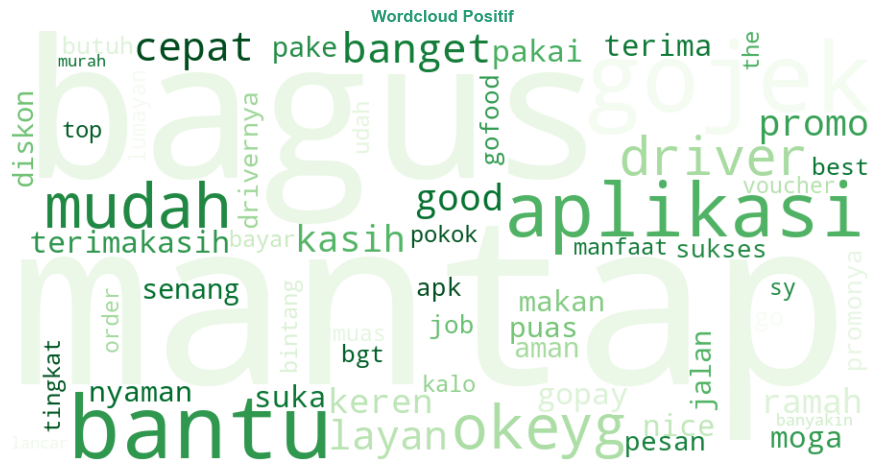

In [95]:
from collections import Counter
from wordcloud import WordCloud

# Filter tampilan tidak mengubah teks yang digunakan model.
teks_positif = ' '.join(data_latih.loc[data_latih['sentimen'] == 'positif', 'text_final'])
kata_positif = Counter(kata for kata in teks_positif.split() if kata not in stopword_visual)
assert not set(kata_positif) & stopword_visual

awan_positif = WordCloud(width=900, height=450, background_color='white',
                        max_words=60, colormap='Greens', random_state=42)
awan_positif.generate_from_frequencies(kata_positif)
plt.figure(figsize=(9, 5))
plt.imshow(awan_positif, interpolation='bilinear')
plt.title('Wordcloud Positif', color=warna_sentimen['positif'])
plt.axis('off')
plt.tight_layout()
plt.show()

Wordcloud positif menunjukkan kata yang sering muncul pada ulasan berating 4 dan 5.

#### Wordcloud Netral

Gunakan langkah yang sama untuk ulasan berating 3, dengan tema kuning.

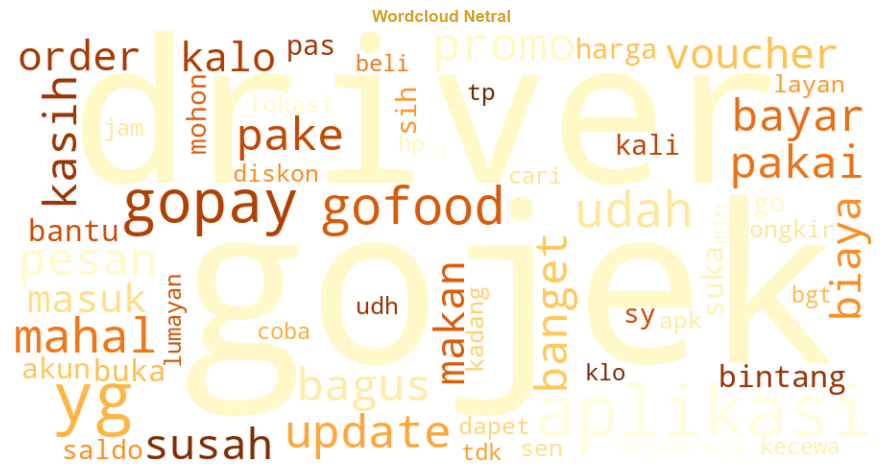

In [96]:
# Filter kata untuk visualisasi netral, bukan untuk model.
teks_netral = ' '.join(data_latih.loc[data_latih['sentimen'] == 'netral', 'text_final'])
kata_netral = Counter(kata for kata in teks_netral.split() if kata not in stopword_visual)
assert not set(kata_netral) & stopword_visual

awan_netral = WordCloud(width=900, height=450, background_color='white',
                       max_words=60, colormap='YlOrBr', random_state=42)
awan_netral.generate_from_frequencies(kata_netral)
plt.figure(figsize=(9, 5))
plt.imshow(awan_netral, interpolation='bilinear')
plt.title('Wordcloud Netral', color=warna_sentimen['netral'])
plt.axis('off')
plt.tight_layout()
plt.show()

Wordcloud netral memperlihatkan kata pada ulasan berating 3, kata pujian dan keluhan bisa muncul bersama.

#### Wordcloud Negatif

Menghitung kata pada ulasan berating 1 dan 2, lalu menampilkan dengan tema merah.

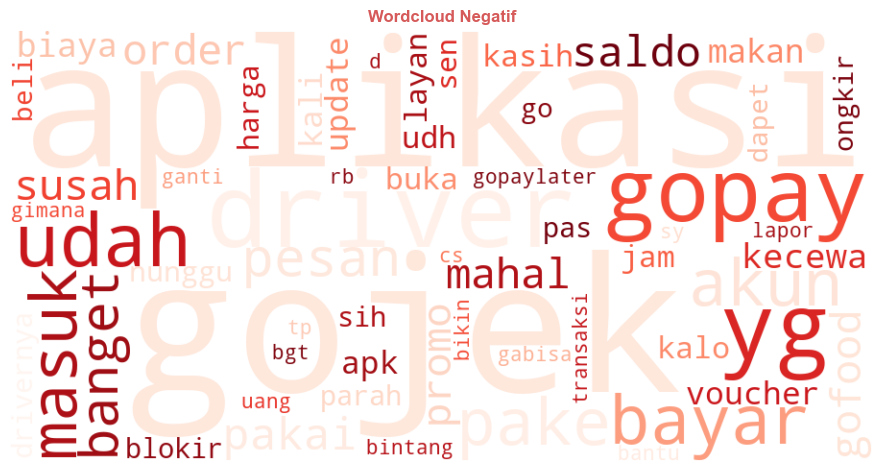

In [97]:
# Filter kata untuk visualisasi negatif, bukan untuk model.
teks_negatif = ' '.join(data_latih.loc[data_latih['sentimen'] == 'negatif', 'text_final'])
kata_negatif = Counter(kata for kata in teks_negatif.split() if kata not in stopword_visual)
assert not set(kata_negatif) & stopword_visual

awan_negatif = WordCloud(width=900, height=450, background_color='white',
                        max_words=60, colormap='Reds', random_state=42)
awan_negatif.generate_from_frequencies(kata_negatif)
plt.figure(figsize=(9, 5))
plt.imshow(awan_negatif, interpolation='bilinear')
plt.title('Wordcloud Negatif', color=warna_sentimen['negatif'])
plt.axis('off')
plt.tight_layout()
plt.show()

Wordcloud negatif menunjukkan kata pada ulasan berating 1 dan 2. Ukuran kata pada semua wordcloud menunjukkan frekuensi, bukan bobot TF-IDF.

### Donut 20 Kata Teratas

Visuaisasi 20 kata-kata yang sering muncul pada setiap sentimen.

#### Donut Positif

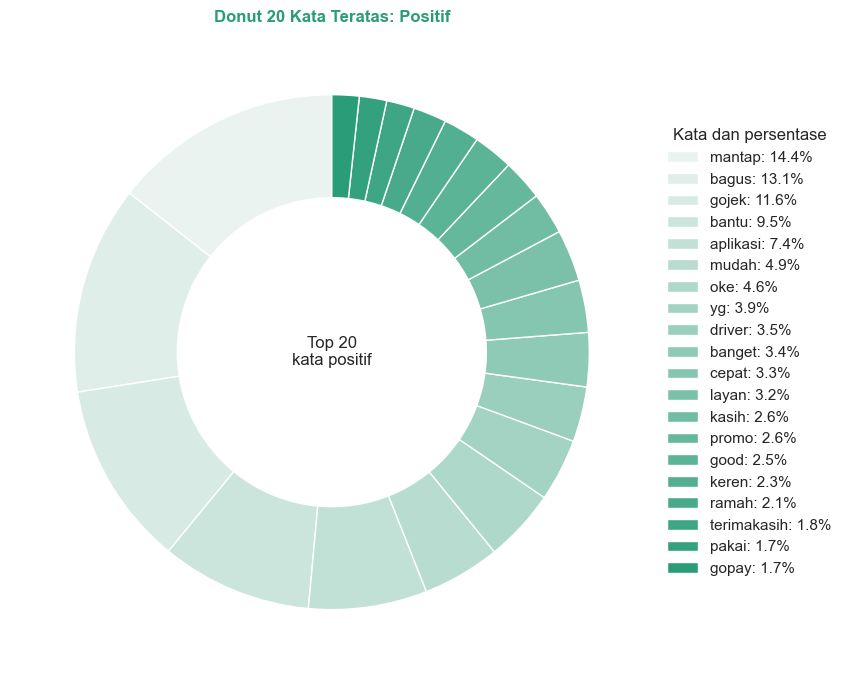

In [98]:
# Ambil 20 kata positif yang paling sering muncul.
top20_positif = pd.Series(dict(kata_positif.most_common(20)))
persen_positif = top20_positif / top20_positif.sum() * 100
legenda_positif = top20_positif.index + ': ' + persen_positif.round(1).astype(str) + '%'

# Persentase hanya memakai total kemunculan 20 kata teratas.
plt.figure(figsize=(10, 7))
irisan_positif, _ = plt.pie(top20_positif.values, startangle=90,
                           colors=sns.light_palette(warna_sentimen['positif'], n_colors=len(top20_positif)),
                           wedgeprops={'width': 0.4, 'edgecolor': 'white'})
plt.text(0, 0, 'Top 20\nkata positif', ha='center', va='center')
plt.legend(irisan_positif, legenda_positif, title='Kata dan persentase',
           loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.title('Donut 20 Kata Teratas: Positif', color=warna_sentimen['positif'])
plt.tight_layout()
plt.show()

20 kata teratas pada sentimen positif.

#### Donut 20 Kata Netral

Visualisasi 20 kata yang paling sering pada kelas netral.

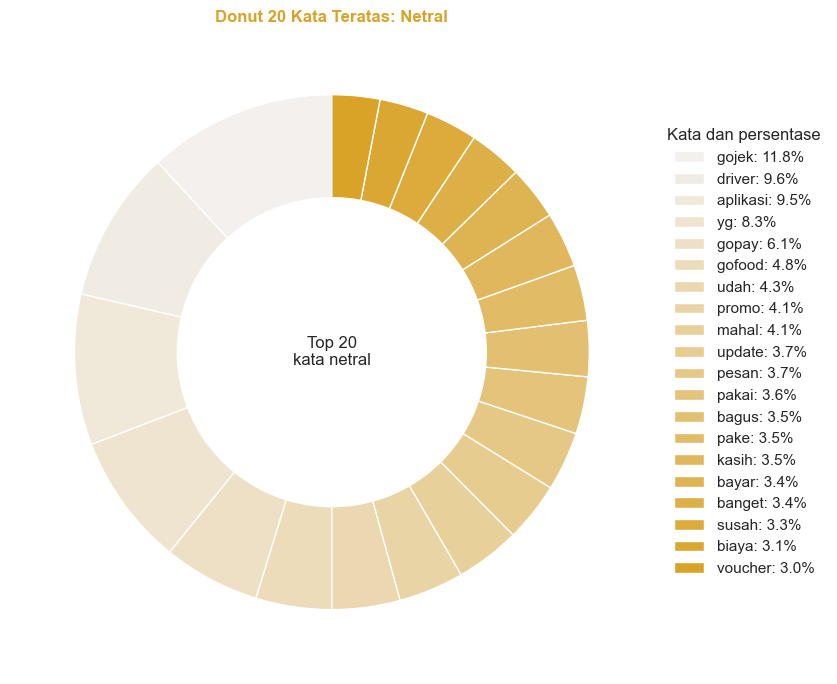

In [99]:
# Ambil 20 kata netral yang paling sering muncul.
top20_netral = pd.Series(dict(kata_netral.most_common(20)))
persen_netral = top20_netral / top20_netral.sum() * 100
legenda_netral = top20_netral.index + ': ' + persen_netral.round(1).astype(str) + '%'

# Buat satu donut netral dengan legenda di kanan.
plt.figure(figsize=(10, 7))
irisan_netral, _ = plt.pie(top20_netral.values, startangle=90,
                          colors=sns.light_palette(warna_sentimen['netral'], n_colors=len(top20_netral)),
                          wedgeprops={'width': 0.4, 'edgecolor': 'white'})
plt.text(0, 0, 'Top 20\nkata netral', ha='center', va='center')
plt.legend(irisan_netral, legenda_netral, title='Kata dan persentase',
           loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.title('Donut 20 Kata Teratas: Netral', color=warna_sentimen['netral'])
plt.tight_layout()
plt.show()

Persentase donut netral memakai total frekuensi 20 kata netral yang dipilih.

#### Donut 20 Kata Negatif

Visualisasi 20 kata yang sering muncul pada kelas atau dengan sentimen negatif.

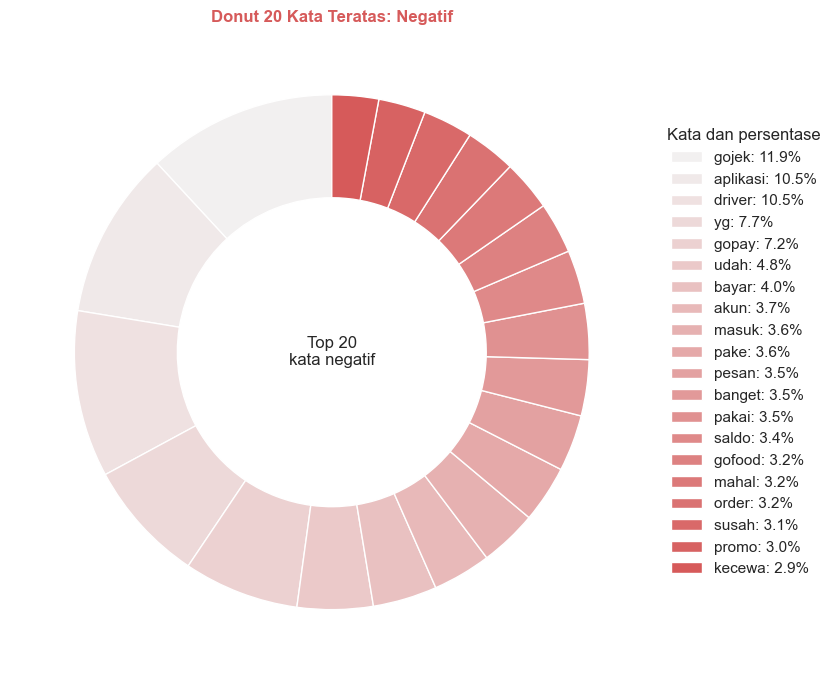

In [100]:
# Ambil 20 kata negatif yang paling sering muncul.
top20_negatif = pd.Series(dict(kata_negatif.most_common(20)))
persen_negatif = top20_negatif / top20_negatif.sum() * 100
legenda_negatif = top20_negatif.index + ': ' + persen_negatif.round(1).astype(str) + '%'

# Buat satu donut negatif dengan legenda di kanan.
plt.figure(figsize=(10, 7))
irisan_negatif, _ = plt.pie(top20_negatif.values, startangle=90,
                           colors=sns.light_palette(warna_sentimen['negatif'], n_colors=len(top20_negatif)),
                           wedgeprops={'width': 0.4, 'edgecolor': 'white'})
plt.text(0, 0, 'Top 20\nkata negatif', ha='center', va='center')
plt.legend(irisan_negatif, legenda_negatif, title='Kata dan persentase',
           loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.title('Donut 20 Kata Teratas: Negatif', color=warna_sentimen['negatif'])
plt.tight_layout()
plt.show()

Ketiga donut membandingkan kata di dalam masing-masing kelas. Kata di luar 20 teratas tidak masuk perhitungan persentase. Kata umum seperti `gojek` muncul pada semua kelas, sehingga frekuensi kata saja belum membuktikan tema keluhan.

## 7. Membuat Fitur TF-IDF

TF-IDF mengubah teks menjadi angka. Kosakata hanya dipelajari dari data latih, validasi dan uji menggunakan kosakata yang sama.

In [101]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Pelajari kosakata dari data latih.
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_train = tfidf.fit_transform(data_latih['text_final'])
X_val = tfidf.transform(data_validasi['text_final'])
X_test = tfidf.transform(data_uji['text_final'])
print('Ukuran matriks latih:', X_train.shape)
print('Ukuran matriks validasi:', X_val.shape)
print('Ukuran matriks uji:', X_test.shape)

Ukuran matriks latih: (124170, 5000)
Ukuran matriks validasi: (25389, 5000)
Ukuran matriks uji: (25094, 5000)


Ketiga matriks memiliki jumlah kolom fitur yang sama.

## 8. Training Model

Model akan dilatih dengan Naive Bayes dan Logistic Regression.
Naive Bayes memakai probabilitas fitur untuk menentukan kelas. Logistic Regression mempelajari bobot setiap fitur. Keduanya dilatih dengan data latih yang sama.

In [102]:
# Latih kedua model pada data latih; prediksi hanya validasi untuk perbandingan.
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
import time

nb_model = MultinomialNB()
lr_model = LogisticRegression(max_iter=1000, random_state=42)
for nama, model in [('Naive Bayes', nb_model), ('Logistic Regression', lr_model)]:
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    print(f'{nama}: waktu latih {time.perf_counter() - t0:.2f} detik')

y_pred_nb = nb_model.predict(X_val)
y_pred_lr = lr_model.predict(X_val)
print(pd.DataFrame({'Asli': y_val.to_numpy(), 'Naive Bayes': y_pred_nb, 'Logistic Regression': y_pred_lr}).head())

Naive Bayes: waktu latih 0.16 detik
Logistic Regression: waktu latih 4.00 detik
      Asli Naive Bayes Logistic Regression
0  negatif     positif             positif
1  negatif     negatif             negatif
2  negatif     negatif             negatif
3  positif     positif             positif
4  positif     positif             positif


Prediksi pada data validasi digunakan untuk membandingkan model.

## 9. Evaluasi Validasi

Accuracy menunjukkan proporsi prediksi benar. 
F1 macro memberi setiap kelas bobot yang sama sehingga kelas netral ikut diperhatikan. 
Sebagai pembanding, baseline selalu memilih kelas mayoritas. 
Classification report dan confusion matrix menunjukkan hasil tiap kelas.

In [103]:
# Hitung metrik dengan penanganan kelas yang tidak mendapat prediksi.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.dummy import DummyClassifier

kelas = ['negatif', 'netral', 'positif']
def evaluasi_model(nama, y_true, y_pred):
    """Metrik keseluruhan; setiap kelas memiliki bobot sama pada F1 macro."""
    return {
        'Model': nama,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, labels=kelas, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, labels=kelas, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, labels=kelas, average='weighted', zero_division=0),
        'F1-Macro': f1_score(y_true, y_pred, labels=kelas, average='macro', zero_division=0)
    }

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
hasil_nb = evaluasi_model('Naive Bayes', y_val, y_pred_nb)
hasil_lr = evaluasi_model('Logistic Regression', y_val, y_pred_lr)
hasil_baseline = evaluasi_model('Baseline mayoritas', y_val, baseline.predict(X_val))
df_eval = pd.DataFrame([hasil_nb, hasil_lr]).set_index('Model')
print('Metrik validasi:')
print(pd.DataFrame([hasil_baseline, hasil_nb, hasil_lr]).set_index('Model').round(4))
for nama, prediksi in [('Naive Bayes', y_pred_nb), ('Logistic Regression', y_pred_lr)]:
    print('\nClassification report validasi:', nama)
    print(classification_report(y_val, prediksi, labels=kelas, zero_division=0))

Metrik validasi:
                     Accuracy  Precision  Recall  F1-Score  F1-Macro
Model                                                               
Baseline mayoritas     0.5382     0.2897  0.5382    0.3767    0.2333
Naive Bayes            0.8155     0.7819  0.8155    0.7909    0.5605
Logistic Regression    0.8217     0.7950  0.8217    0.7968    0.5705

Classification report validasi: Naive Bayes
              precision    recall  f1-score   support

     negatif       0.73      0.91      0.81     10103
      netral       0.10      0.00      0.00      1621
     positif       0.90      0.84      0.87     13665

    accuracy                           0.82     25389
   macro avg       0.58      0.58      0.56     25389
weighted avg       0.78      0.82      0.79     25389


Classification report validasi: Logistic Regression
              precision    recall  f1-score   support

     negatif       0.77      0.86      0.81     10103
      netral       0.36      0.01      0.02      1

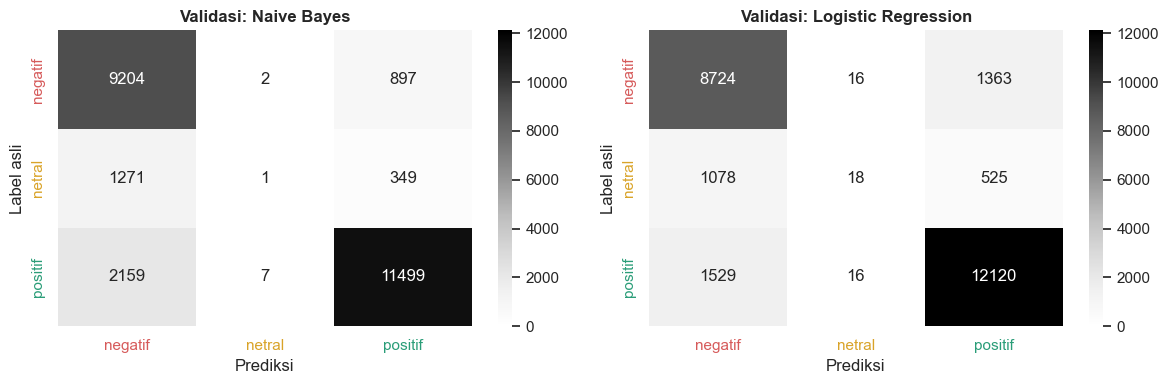

In [104]:
# Warna abu-abu menunjukkan jumlah; warna label menunjukkan sentimen.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
batas_warna = max(confusion_matrix(y_val, prediksi, labels=kelas).max() for prediksi in [y_pred_nb, y_pred_lr])
for kanvas, nama, prediksi in zip(axes, ['Naive Bayes', 'Logistic Regression'], [y_pred_nb, y_pred_lr]):
    matriks = confusion_matrix(y_val, prediksi, labels=kelas)
    sns.heatmap(matriks, annot=True, fmt='d', cmap='Greys', vmin=0, vmax=batas_warna,
                xticklabels=kelas, yticklabels=kelas, ax=kanvas)
    for label in kanvas.get_xticklabels() + kanvas.get_yticklabels():
        label.set_color(warna_sentimen[label.get_text()])
    kanvas.set_title('Validasi: ' + nama)
    kanvas.set_xlabel('Prediksi')
    kanvas.set_ylabel('Label asli')
plt.tight_layout()
plt.show()

Periksa skor tiap kelas, terutama netral yang jumlahnya sedikit.

## 10. Seleksi Model

Pilih model dengan F1 macro validasi tertinggi. Tiga contoh ulasan berikut hanya untuk mencoba prediksi, bukan untuk mengukur akurasi.

In [105]:
# Pilih kandidat berdasarkan F1 macro pada validasi.
model_terbaik_nama = df_eval['F1-Macro'].idxmax()
model_terbaik = {'Naive Bayes': nb_model, 'Logistic Regression': lr_model}[model_terbaik_nama]
print('Model terpilih:', model_terbaik_nama)
if df_eval.loc[model_terbaik_nama, 'F1-Macro'] <= hasil_baseline['F1-Macro']:
    print('Model belum melampaui baseline.')

def prediksi_sentimen(teks):
    teks_bersih = preprocessing_teks(bersihkan_teks(teks))
    fitur_baru = tfidf.transform([teks_bersih])
    if fitur_baru.nnz == 0:
        raise ValueError('Teks kosong atau tidak dikenali kosakata model.')
    return model_terbaik.predict(fitur_baru)[0]

# Coba beberapa ulasan, tanpa menganggapnya sebagai data uji berlabel.
ulasan_baru = ['Aplikasi sangat membantu dan driver ramah', 'Pembayaran gagal saya kecewa', 'Aplikasi oke tetapi kadang lambat']
for ulasan in ulasan_baru:
    print(ulasan, '=>', prediksi_sentimen(ulasan))

Model terpilih: Logistic Regression
Aplikasi sangat membantu dan driver ramah => positif
Pembayaran gagal saya kecewa => negatif
Aplikasi oke tetapi kadang lambat => positif


Nama model terpilih dan hasil prediksi mengikuti output kode.

## 11. Ringkasan dan Pengujian Akhir

Tabel berikut mencatat jumlah baris pada setiap tahap. Setelah itu, model terpilih dinilai pada data uji yang tidak digunakan untuk pemilihan model.

In [106]:
# Catat jumlah baris pada setiap tahap, termasuk cabang subset.
jumlah_final = len(data_latih) + len(data_validasi) + len(data_uji)
jejak_baris = [
    ('Data awal', 'Semua', jumlah_awal, jumlah_awal),
    ('Pelabelan', 'Semua', jumlah_awal, jumlah_awal),
    ('Pembersihan dasar', 'Semua', jumlah_awal, len(df)),
    ('Pembagian data', 'Semua', len(df), len(indeks_latih) + len(indeks_validasi) + len(indeks_uji)),
    ('Preprocessing dan filter', 'Latih', len(indeks_latih), len(data_latih)),
    ('Preprocessing dan filter', 'Validasi', len(indeks_validasi), len(data_validasi)),
    ('Preprocessing dan filter', 'Uji', len(indeks_uji), len(data_uji)),
    ('Total setelah preprocessing', 'Semua', len(df), jumlah_final),
    ('TF-IDF', 'Latih', len(data_latih), X_train.shape[0]),
    ('TF-IDF', 'Validasi', len(data_validasi), X_val.shape[0]),
    ('TF-IDF', 'Uji', len(data_uji), X_test.shape[0]),
    ('Pelatihan model', 'Latih', X_train.shape[0], len(y_train)),
    ('Evaluasi validasi', 'Validasi', X_val.shape[0], len(y_pred_lr)),
    ('Evaluasi akhir', 'Uji', X_test.shape[0], len(y_test))
]
tabel_ringkasan_baris = pd.DataFrame(jejak_baris, columns=['Tahap', 'Subset', 'Baris Sebelum', 'Baris Sesudah'])
tabel_ringkasan_baris['Baris Berkurang'] = tabel_ringkasan_baris['Baris Sebelum'] - tabel_ringkasan_baris['Baris Sesudah']
assert len(indeks_latih) + len(indeks_validasi) + len(indeks_uji) == len(df)
assert (tabel_ringkasan_baris['Baris Berkurang'] >= 0).all()
display(tabel_ringkasan_baris)

,Tahap,Subset,Baris Sebelum,Baris Sesudah,Baris Berkurang
0,Data awal,Semua,225002,225002,0
1,Pelabelan,Semua,225002,225002,0
2,Pembersihan dasar,Semua,225002,224890,112
3,Pembagian data,Semua,224890,224890,0
4,Preprocessing dan filter,Latih,137939,124170,13769
5,Preprocessing dan filter,Validasi,37359,25389,11970
6,Preprocessing dan filter,Uji,49592,25094,24498
7,Total setelah preprocessing,Semua,224890,174653,50237
8,TF-IDF,Latih,124170,124170,0
9,TF-IDF,Validasi,25389,25389,0


### Hasil Uji

Distribusi label pada data eksperimen dan bandingkan model terpilih dengan baseline pada data uji.

In [107]:
# Ringkasan statistik menggunakan baris yang benar-benar masuk eksperimen.
data_eksperimen = pd.concat([data_latih, data_validasi, data_uji])
print(f'Jumlah ulasan eksperimen: {len(data_eksperimen):,}')
print(f'Baris dikeluarkan setelah pembagian: {len(df) - len(data_eksperimen):,}')
ringkasan_label = data_eksperimen['sentimen'].value_counts().rename('Jumlah').to_frame()
ringkasan_label['Persentase'] = ringkasan_label['Jumlah'] / len(data_eksperimen) * 100
print(ringkasan_label.round(2))

# Uji akhir hanya untuk kandidat yang sudah dipilih dari validasi.
y_pred_final = model_terbaik.predict(X_test)
hasil_uji = evaluasi_model(model_terbaik_nama, y_test, y_pred_final)
hasil_uji_baseline = evaluasi_model('Baseline mayoritas', y_test, baseline.predict(X_test))
print('\nHasil uji akhir:')
print(pd.DataFrame([hasil_uji_baseline, hasil_uji]).set_index('Model').round(4))
print(classification_report(y_test, y_pred_final, labels=kelas, zero_division=0))

Jumlah ulasan eksperimen: 174,653
Baris dikeluarkan setelah pembagian: 50,237
          Jumlah  Persentase
sentimen                    
positif   113342       64.90
negatif    52594       30.11
netral      8717        4.99

Hasil uji akhir:
                     Accuracy  Precision  Recall  F1-Score  F1-Macro
Model                                                               
Baseline mayoritas     0.5339     0.2851  0.5339    0.3717    0.2320
Logistic Regression    0.8191     0.7924  0.8191    0.7940    0.5685
              precision    recall  f1-score   support

     negatif       0.77      0.87      0.81     10080
      netral       0.36      0.01      0.02      1616
     positif       0.86      0.88      0.87     13398

    accuracy                           0.82     25094
   macro avg       0.66      0.59      0.57     25094
weighted avg       0.79      0.82      0.79     25094



## Kesimpulan

Dengan stemming Sastrawi aktif, Logistic Regression memperoleh F1 macro validasi 0,5705, dibanding Naive Bayes 0,5605. Evaluasi ulang pada holdout yang sama menghasilkan akurasi 81,91%, F1 weighted 0,7940, dan F1 macro 0,5685. Baseline mayoritas mendapat F1 macro 0,2320. Ini hasil eksperimen revisi, bukan uji independen baru.

Recall netral sekitar 0,01 menunjukkan bahwa model masih sulit mengenali kelas ini. Stemming belum dapat dinyatakan meningkatkan atau menurunkan kualitas model berdasarkan perbandingan langsung dengan eksperimen sebelumnya, karena baris yang lolos filter berubah. Perbandingan yang adil membutuhkan baris evaluasi yang sama.

Sebanyak 174.653 ulasan masuk eksperimen: 124.170 latih, 25.389 validasi, dan 25.094 uji. Label berasal dari rating, emoji dihapus, dan sebagian teks tersaring. Negasi tetap digunakan model tetapi disembunyikan dari grafik kata. Stemming pertama mencatat sekitar 47.760 detik; cache disimpan untuk penggunaan berikutnya.